# ADS-509 Final Project
## Collecting Text Data via API and Web Scraping


# Project requirements:

- Gather and prepare a text-based dataset (e.g., reviews, news articles, or social media posts).
- Conduct an EDA focused on text structure, frequency patterns, and sentiment or topic distributions (similar to the steps completed in Modules 2 and 3).
- Fine-tune or adapt an existing open-source LLM for a specific task (e.g., text classification, topic prediction, or sentiment analysis).
- Demonstrate how generative AI tools were used to assist in code generation, model implementation, or visualization creation.



We will collect Steam user reviews from five popular games to include a variety of player opinions.

**Selected games:**
- Elden Ring
- Cyberpunk 2077
- No Man's Sky
- Cities: Skylines II
- Stardew Valley

Our goal is to collect 1,000 reviews per game, with 500 positive and 500 negative reviews. However, the final number will depend on the reviews available through the Steam API.



We begin by importing the required libraries and creating folders to store the data collected through the Steam API.


In [4]:
import os, json, time, random
import requests
import pandas as pd

# Create folders for collected data
DATA_DIR = "data/steam"
RAW_API_DIR = os.path.join(DATA_DIR, "raw_api")

for d in [DATA_DIR, RAW_API_DIR]:
    os.makedirs(d, exist_ok=True)

# Request header
HEADERS = {
    "User-Agent": "ADS509-Student-Project/1.0"}

# Steam Reviews API
BASE = "https://api.steampowered.com/IUserReviewsService/GetAppReviews/v1/"

In [5]:
# Elden Ring Steam App ID
APP_ID = 1245620

# Request 10 English reviews to test the API
params = {
    "input_json": json.dumps({
        "appid": APP_ID,
        "languages": ["english"],
        "num_per_page": 10})}

# Send request to Steam API
r = requests.get(BASE, params=params, headers=HEADERS, timeout=60)
r.raise_for_status()

data = r.json()

print(data.keys())

dict_keys(['response'])


In [6]:
# Get the data inside the response
steam_data = data["response"]

# Check the fields returned by Steam
print(steam_data.keys())

dict_keys(['query_summary', 'reviews', 'cursor', 'day_range_used', 'total_matching'])


In [7]:
# Check how many reviews were returned
print("Number of reviews:", len(steam_data["reviews"]))

# Look at the first review
print(steam_data["reviews"][0])

Number of reviews: 10
{'recommendationid': '235803017', 'author': {'steamid': '76561199802535482', 'num_reviews': 4, 'playtime_forever': 7784, 'playtime_last_two_weeks': 0, 'playtime_at_review': 6129, 'last_played': 1790732209}, 'language': 'english', 'review': "[h1]600+ Hours In-Depth Review | Played Across PC & Console[/h1]\n\n[b]Rating:[/b] 10 / 10\n[b]Verdict:[/b] An absolute masterpiece worth every single cent at full price. I bought this game three separate times—digitally on PlayStation with the DLC ($80), as a physical disc, and again on Steam with the DLC ($80). That alone speaks for itself.\n\n[hr][/hr]\n\n[h2]Gameplay, Freedom, & Build Crafting[/h2]\nThe build variety is virtually limitless. Whether you run pure Strength with colossal weapons, agile Dexterity, Sorceries, Faith, Arcane, or hybrid setups, every archetype feels mechanically distinct. When you factor in the extensive buff stacking system, stance-breaking (poise break), and weapon affinities, you can tailor your 

In [8]:
   # Save the test API response as raw JSON
fp = os.path.join(RAW_API_DIR, "elden_ring_test.json")

with open(fp, "w", encoding="utf-8") as f:
    json.dump(data, f)

print("Saved:", fp)

Saved: data/steam/raw_api/elden_ring_test.json


We created a function to collect Steam reviews through the API and save the raw response as a JSON file. This allows us to reuse the function when collecting reviews from different games.

In [10]:
def fetch_reviews(app_id, game_name, num_reviews=100):
    
    # Request reviews from Steam
    params = {
        "input_json": json.dumps({
            "appid": app_id,
            "languages": ["english"],
            "num_per_page": num_reviews})}

    r = requests.get(BASE, params=params, headers=HEADERS, timeout=60)
    r.raise_for_status()
    data = r.json()

    # Save raw API response
    fp = os.path.join(RAW_API_DIR, f"{game_name}_reviews.json")
    with open(fp, "w", encoding="utf-8") as f:
        json.dump(data, f)

    return data

We test the function by collecting 100 English reviews for Elden Ring and checking the number of reviews returned.

In [12]:
elden_data = fetch_reviews(
    app_id=1245620,
    game_name="elden_ring",
    num_reviews=100)

elden_reviews = elden_data["response"]["reviews"]

print("Reviews collected:", len(elden_reviews))

Reviews collected: 100


## Pagination - Collect multiple pages automatically

We create a function that uses the cursor to collect multiple pages of reviews until we reach our target or no more reviews are returned.

In [14]:
# Check the cursor used to retrieve the next page
cursor = elden_data["response"]["cursor"]

print("Cursor:", cursor)

Cursor: AoIFQFaAAAAAAAB6jMyJBw==


In [15]:
def collect_reviews(app_id, target, review_type):
    all_reviews = []
    cursor = "*"

    while len(all_reviews) < target:

        # Request reviews of the selected type
        params = {
            "input_json": json.dumps({
                "appid": app_id,
                "languages": ["english"],
                "review_type": review_type,
                "day_range": 365,
                "num_per_page": 100,
                "cursor": cursor})
        }

        r = requests.get(BASE, params=params, headers=HEADERS, timeout=60)
        r.raise_for_status()
        data = r.json()

        # Get reviews safely
        reviews = data["response"].get("reviews", [])

        # Stop if no reviews are returned
        if not reviews:
            print("API response:", data["response"])
            print("No more reviews returned.")
            break

        all_reviews.extend(reviews)

        # Get cursor for next page
        cursor = data["response"].get("cursor")

        print("Reviews collected:", len(all_reviews))

        time.sleep(1)

    return all_reviews[:target]

In [16]:
# Collect 500 Elden Ring reviews (0 = all reviews)
elden_reviews = collect_reviews(
    app_id=1245620,
    target=500,
    review_type=0)

print("Total Elden Ring reviews:", len(elden_reviews))

Reviews collected: 100
Reviews collected: 200
Reviews collected: 300
Reviews collected: 400
Reviews collected: 500
Total Elden Ring reviews: 500


Check positive vs. negative reviews : 
We check the distribution of positive and negative reviews to see whether the collected data is balanced before collecting the final dataset.

In [18]:
# Count positive and negative reviews
positive = sum(review["voted_up"] for review in elden_reviews)
negative = len(elden_reviews) - positive

print("Positive reviews:", positive)
print("Negative reviews:", negative)

Positive reviews: 455
Negative reviews: 45


he initial 500 Elden Ring reviews contain 455 positive and 45 negative reviews. Since the dataset is imbalanced, we will test whether the Steam API allows us to collect negative reviews separately.

In [20]:
# Request negative reviews only
params = {
    "input_json": json.dumps({
        "appid": 1245620,
        "languages": ["english"],
        "review_type": 2,#IUserReviewsService API,review_type is an integer not the string.0=all,1=positive,2=negative. 
        "num_per_page": 100})}

r = requests.get(BASE, params=params, headers=HEADERS, timeout=60)
r.raise_for_status()

negative_data = r.json()
negative_reviews = negative_data["response"]["reviews"]

# Check the results
print("Reviews returned:", len(negative_reviews))
print("Negative reviews:", sum(not review["voted_up"] for review in negative_reviews))

Reviews returned: 100
Negative reviews: 100


In [21]:
# 1 = positive, 2 = negative
more_positive = collect_reviews(1245620, 80, 1) ## only collect what we need/what we missing
more_negative = collect_reviews(1245620, 420, 2) ## only collect what we need/what we missing

print("Additional positive:", len(more_positive))
print("Additional negative:", len(more_negative))

Reviews collected: 100
Reviews collected: 100
Reviews collected: 199
Reviews collected: 299
Reviews collected: 399
Reviews collected: 499
Additional positive: 80
Additional negative: 420


We should save the 547 unique reviews we've collected before making further changes.

In [23]:
# Combine original and additional reviews
all_elden_reviews = elden_reviews + more_positive + more_negative

# Convert to DataFrame
elden_df = pd.DataFrame(all_elden_reviews)

# Remove duplicate reviews
elden_df = elden_df.drop_duplicates(subset="recommendationid")

# Check total and sentiment distribution
print("Total unique reviews:", len(elden_df))
print(elden_df["voted_up"].value_counts())

Total unique reviews: 875
voted_up
True     455
False    420
Name: count, dtype: int64


We combine the original and additional reviews and remove duplicates using recommendationid. This ensures each review appears only once in our dataset.

### Save collected reviews

We save the unique Elden Ring reviews as a CSV file. This dataset will be used for text cleaning, exploratory data analysis, and sentiment classification.

In [26]:
# Save unique reviews to CSV
fp = os.path.join(DATA_DIR, "elden_ring_reviews.csv")

elden_df.to_csv(fp, index=False)

print("Saved:", fp)
print("Total unique reviews:", len(elden_df))

Saved: data/steam/elden_ring_reviews.csv
Total unique reviews: 875


In [27]:
# Check positive and negative reviews
print(elden_df["voted_up"].value_counts())

voted_up
True     455
False    420
Name: count, dtype: int64


After removing duplicates, we collected 875 unique reviews: 455 positive (52%) and 420 negative (48%). The dataset is now nearly balanced and ready for the next stage of data collection.



### Collecting Cyberpunk 2077 Reviews

We use the same Steam API function to collect English reviews for Cyberpunk 2077. Our goal is to collect 500 positive and 500 negative reviews.

In [30]:
# Collect 500 positive reviews
cyberpunk_positive = collect_reviews(1091500, 500, 1)

# Collect 500 negative reviews
cyberpunk_negative = collect_reviews(1091500, 500, 2)

# Check collected reviews
print("Positive reviews:", len(cyberpunk_positive))
print("Negative reviews:", len(cyberpunk_negative))

Reviews collected: 100
Reviews collected: 200
Reviews collected: 300
Reviews collected: 400
Reviews collected: 500
Reviews collected: 100
Reviews collected: 200
Reviews collected: 300
Reviews collected: 400
Reviews collected: 500
Positive reviews: 500
Negative reviews: 500


### Combining Cyberpunk 2077 Reviews

Let's combine the positive and negative reviews into one DataFrame. We will remove duplicate reviews using `recommendationid` and check the final sentiment distribution.

In [32]:
# Combine positive and negative reviews
all_cyberpunk_reviews = cyberpunk_positive + cyberpunk_negative

# Convert to DataFrame and remove duplicates
cyberpunk_df = pd.DataFrame(all_cyberpunk_reviews)
cyberpunk_df = cyberpunk_df.drop_duplicates(subset="recommendationid")

# Check unique reviews and sentiment counts
print("Total unique reviews:", len(cyberpunk_df))
print(cyberpunk_df["voted_up"].value_counts())

Total unique reviews: 1000
voted_up
True     500
False    500
Name: count, dtype: int64


### Saving Cyberpunk 2077 Reviews

We save the unique Cyberpunk 2077 reviews to a CSV file for later cleaning, exploratory data analysis, and sentiment modeling.

In [34]:
# Save unique Cyberpunk 2077 reviews to CSV
fp = os.path.join(DATA_DIR, "cyberpunk_2077_reviews.csv")

cyberpunk_df.to_csv(fp, index=False)

# Confirm the saved file and review count
print("Saved:", fp)
print("Total unique reviews:", len(cyberpunk_df))

Saved: data/steam/cyberpunk_2077_reviews.csv
Total unique reviews: 1000


### Collecting No Man's Sky Reviews

We use the Steam API to collect English reviews for No Man's Sky. Our goal is to collect 500 positive and 500 negative reviews for sentiment analysis.

In [36]:
# Collect 500 positive reviews
nomanssky_positive = collect_reviews(275850, 500, 1)

# Collect 500 negative reviews
nomanssky_negative = collect_reviews(275850, 500, 2)

# Check the number of reviews collected
print("Positive reviews:", len(nomanssky_positive))
print("Negative reviews:", len(nomanssky_negative))

Reviews collected: 100
Reviews collected: 200
Reviews collected: 300
Reviews collected: 400
Reviews collected: 500
Reviews collected: 100
Reviews collected: 200
Reviews collected: 300
Reviews collected: 400
Reviews collected: 500
Positive reviews: 500
Negative reviews: 500


### Combining No Man's Sky Reviews

We combine the positive and negative reviews into one DataFrame and remove duplicates using `recommendationid`. We then check the total unique reviews and sentiment distribution.

In [38]:
# Combine positive and negative reviews
all_nomanssky_reviews = nomanssky_positive + nomanssky_negative

# Convert to DataFrame and remove duplicates
nomanssky_df = pd.DataFrame(all_nomanssky_reviews)
nomanssky_df = nomanssky_df.drop_duplicates(subset="recommendationid")

# Check unique reviews and sentiment counts
print("Total unique reviews:", len(nomanssky_df))
print(nomanssky_df["voted_up"].value_counts())

Total unique reviews: 1000
voted_up
True     501
False    499
Name: count, dtype: int64


### Saving No Man's Sky Reviews

We save the unique No Man's Sky reviews to a CSV file for later data cleaning, exploratory data analysis, and sentiment classification.

In [40]:
# Save unique No Man's Sky reviews to CSV
fp = os.path.join(DATA_DIR, "no_mans_sky_reviews.csv")

nomanssky_df.to_csv(fp, index=False)

# Confirm the saved file and total reviews
print("Saved:", fp)
print("Total unique reviews:", len(nomanssky_df))

Saved: data/steam/no_mans_sky_reviews.csv
Total unique reviews: 1000


### Collecting Cities: Skylines II Reviews

We use the Steam API to collect English reviews for Cities: Skylines II. Our goal is to collect 500 positive and 500 negative reviews for sentiment analysis.

In [42]:
# Collect 500 positive reviews
cities_positive = collect_reviews(949230, 500, 1)

# Collect 500 negative reviews
cities_negative = collect_reviews(949230, 500, 2)

# Check the number of reviews collected
print("Positive reviews:", len(cities_positive))
print("Negative reviews:", len(cities_negative))

Reviews collected: 100
Reviews collected: 200
Reviews collected: 300
Reviews collected: 400
Reviews collected: 500
Reviews collected: 100
Reviews collected: 200
Reviews collected: 300
Reviews collected: 400
Reviews collected: 500
Positive reviews: 500
Negative reviews: 500


### Combining Cities: Skylines II Reviews

We combine the positive and negative reviews into one DataFrame. We remove duplicate reviews using `recommendationid` and check the sentiment distribution.

In [44]:
# Combine positive and negative reviews
all_cities_reviews = cities_positive + cities_negative

# Convert to DataFrame and remove duplicates
cities_df = pd.DataFrame(all_cities_reviews)
cities_df = cities_df.drop_duplicates(subset="recommendationid")

# Check unique reviews and sentiment counts
print("Total unique reviews:", len(cities_df))
print(cities_df["voted_up"].value_counts())

Total unique reviews: 1000
voted_up
True     500
False    500
Name: count, dtype: int64


### Saving Cities: Skylines II Reviews

We save the unique Cities: Skylines II reviews to a CSV file for later data cleaning, exploratory data analysis, and sentiment classification.

In [46]:
# Save unique Cities: Skylines II reviews to CSV
fp = os.path.join(DATA_DIR, "cities_skylines_ii_reviews.csv")

cities_df.to_csv(fp, index=False)

# Confirm the saved file and review count
print("Saved:", fp)
print("Total unique reviews:", len(cities_df))

Saved: data/steam/cities_skylines_ii_reviews.csv
Total unique reviews: 1000


### Collecting Stardew Valley Reviews

We use the Steam API to collect English reviews for Stardew Valley. Our goal is to collect 500 positive and 500 negative reviews for sentiment analysis.

In [48]:
# Collect 500 positive reviews
stardew_positive = collect_reviews(413150, 500, 1)

# Collect 500 negative reviews
stardew_negative = collect_reviews(413150, 500, 2)

# Check the number of reviews collected
print("Positive reviews:", len(stardew_positive))
print("Negative reviews:", len(stardew_negative))

Reviews collected: 100
Reviews collected: 200
Reviews collected: 300
Reviews collected: 400
Reviews collected: 500
Reviews collected: 100
Reviews collected: 200
Reviews collected: 299
Reviews collected: 399
Reviews collected: 499
Reviews collected: 528
Positive reviews: 500
Negative reviews: 500


### Combining Stardew Valley Reviews

We combine the positive and negative reviews into one DataFrame. We remove duplicate reviews using `recommendationid` and check the final sentiment distribution.

In [50]:
# Combine positive and negative reviews
all_stardew_reviews = stardew_positive + stardew_negative

# Convert to DataFrame and remove duplicates
stardew_df = pd.DataFrame(all_stardew_reviews)
stardew_df = stardew_df.drop_duplicates(subset="recommendationid")

# Check unique reviews and sentiment counts
print("Total unique reviews:", len(stardew_df))
print(stardew_df["voted_up"].value_counts())

Total unique reviews: 1000
voted_up
True     500
False    500
Name: count, dtype: int64


### Saving Stardew Valley Reviews

We save the unique Stardew Valley reviews to a CSV file for later data cleaning, exploratory data analysis, and sentiment classification.

In [52]:
# Save unique Stardew Valley reviews to CSV
fp = os.path.join(DATA_DIR, "stardew_valley_reviews.csv")

stardew_df.to_csv(fp, index=False)

# Confirm the saved file and total reviews
print("Saved:", fp)
print("Total unique reviews:", len(stardew_df))

Saved: data/steam/stardew_valley_reviews.csv
Total unique reviews: 1000


## Combining Reviews from All Five Games

We combine the five game datasets into one DataFrame. We also add a game name column to identify which game each review belongs to.

In [54]:
# Add game names to each dataset
elden_df["game"] = "Elden Ring"
cyberpunk_df["game"] = "Cyberpunk 2077"
nomanssky_df["game"] = "No Man's Sky"
cities_df["game"] = "Cities: Skylines II"
stardew_df["game"] = "Stardew Valley"

# Combine all five datasets
steam_df = pd.concat(
    [elden_df, cyberpunk_df, nomanssky_df, cities_df, stardew_df],ignore_index=True)

# Check total reviews by game
print("Total reviews:", len(steam_df))
print(steam_df["game"].value_counts())

Total reviews: 4875
game
Cyberpunk 2077         1000
No Man's Sky           1000
Cities: Skylines II    1000
Stardew Valley         1000
Elden Ring              875
Name: count, dtype: int64


### Saving the Combined Steam Reviews Dataset

We save the combined reviews from all five games into one CSV file. This dataset will be used for data cleaning, exploratory data analysis (EDA), and sentiment classification.

In [56]:
# Save the combined dataset to CSV
fp = os.path.join(DATA_DIR, "steam_reviews_combined.csv")

steam_df.to_csv(fp, index=False)

# Confirm the saved file and total reviews
print("Saved:", fp)
print("Total reviews:", len(steam_df))

Saved: data/steam/steam_reviews_combined.csv
Total reviews: 4875


## Data Cleaning and Exploratory Data Analysis (EDA)

We begin by exploring the combined Steam reviews dataset. We check its structure, columns, and sample records to understand the data before cleaning.

In [58]:
# Check dataset size and column names
print("Dataset shape:", steam_df.shape)
print("\nColumns:", steam_df.columns.tolist())

# Display the first five reviews
steam_df.head()

Dataset shape: (4875, 19)

Columns: ['recommendationid', 'author', 'language', 'review', 'timestamp_created', 'timestamp_updated', 'voted_up', 'votes_up', 'votes_funny', 'weighted_vote_score', 'comment_count', 'steam_purchase', 'received_for_free', 'written_during_early_access', 'primarily_steam_deck', 'refunded', 'game', 'developer_response', 'timestamp_dev_responded']


,recommendationid,author,language,review,timestamp_created,timestamp_updated,voted_up,votes_up,votes_funny,weighted_vote_score,comment_count,steam_purchase,received_for_free,written_during_early_access,primarily_steam_deck,refunded,game,developer_response,timestamp_dev_responded
0,219038892,"{'steamid': '76561199639220058', 'num_reviews'...",english,found a boss early on \nspent like 1.5 hours t...,1771851446,1771851446,True,423,264,0.953083,38,True,False,False,False,False,Elden Ring,NaN,NaN
1,228836650,"{'steamid': '76561199277891288', 'num_reviews'...",english,please make this game go on sale for 40bucks p...,1782439316,1782439316,True,615,85,0.930133,15,True,False,False,False,False,Elden Ring,NaN,NaN
2,228784430,"{'steamid': '76561198142247081', 'num_reviews'...",english,Let me start off be saying this game is phenom...,1782389197,1782438875,True,177,4,0.920412,4,True,False,False,False,False,Elden Ring,NaN,NaN
3,224742298,"{'steamid': '76561198865232934', 'num_reviews'...",english,I got Elden Ring as a Christmas present from m...,1777882905,1777882905,True,212,43,0.911162,3,True,True,False,False,False,Elden Ring,NaN,NaN
4,208513521,"{'steamid': '76561198962938400', 'num_reviews'...",english,"This game is super hard, I'm not gonna sit her...",1762383238,1762383238,True,135,5,0.879808,1,True,False,False,False,False,Elden Ring,NaN,NaN


### Checking Missing Values and Duplicates

We check for missing values in each column and duplicate review IDs. This helps us identify data quality issues before cleaning the review text.

In [60]:
# Check missing values in each column
print("Missing values:")
print(steam_df.isnull().sum())

# Check duplicate review IDs
print("\nDuplicate reviews:", steam_df["recommendationid"].duplicated().sum())

# Check missing review text
print("Missing review text:", steam_df["review"].isnull().sum())

Missing values:
recommendationid                  0
author                            0
language                          0
review                            0
timestamp_created                 0
timestamp_updated                 0
voted_up                          0
votes_up                          0
votes_funny                       0
weighted_vote_score               0
comment_count                     0
steam_purchase                    0
received_for_free                 0
written_during_early_access       0
primarily_steam_deck              0
refunded                          0
game                              0
developer_response             4874
timestamp_dev_responded        4874
dtype: int64

Duplicate reviews: 0
Missing review text: 0


Even though there are no missing values, some reviews might contain only spaces. Let's check that before cleaning the text.

### Checking Empty Reviews

We check whether any reviews contain only spaces or empty text. These reviews would not provide useful information for sentiment analysis.

In [63]:
# Check reviews containing only spaces or empty text
empty_reviews = steam_df["review"].str.strip().eq("").sum()

print("Empty reviews:", empty_reviews)

Empty reviews: 0


## Clean review text
We'll create a new column called clean_review while keeping the original review column unchanged. We will covert all reviews into lower cases to make them consistent. Removed hyperlink and URL's if any and trim/remove the extra blank spaces.

In [65]:
import re

# Function to clean review text
def clean_text(text):
    text = text.lower()                          # Convert to lowercase
    text = re.sub(r"http\S+|www\S+", "", text)   # Remove URLs
    text = re.sub(r"\s+", " ", text).strip()     # Remove extra spaces
    return text

# Create a new column with cleaned reviews
steam_df["clean_review"] = steam_df["review"].apply(clean_text)

# Compare original and cleaned reviews
steam_df[["review", "clean_review"]].head()

,review,clean_review
0,found a boss early on \nspent like 1.5 hours t...,found a boss early on spent like 1.5 hours try...
1,please make this game go on sale for 40bucks p...,please make this game go on sale for 40bucks p...
2,Let me start off be saying this game is phenom...,let me start off be saying this game is phenom...
3,I got Elden Ring as a Christmas present from m...,i got elden ring as a christmas present from m...
4,"This game is super hard, I'm not gonna sit her...","this game is super hard, i'm not gonna sit her..."


### Sentiment Distribution by Game

We examine the number of positive and negative reviews for each game. This helps us understand the balance of sentiment labels in our dataset.

In [67]:
# Count positive and negative reviews for each game
sentiment_counts = pd.crosstab(steam_df["game"], steam_df["voted_up"])

# Rename columns for readability
sentiment_counts = sentiment_counts.rename(
    columns={True: "Positive", False: "Negative"})

print(sentiment_counts)

voted_up             Negative  Positive
game                                   
Cities: Skylines II       500       500
Cyberpunk 2077            500       500
Elden Ring                420       455
No Man's Sky              499       501
Stardew Valley            500       500


Our combined dataset after clean up contains 4,875 reviews, with 2,456 positive and 2,419 negative reviews. The sentiment distribution is nearly balanced across all five games.

### Visualizing Sentiment Distribution by Game

We create a bar chart to compare positive and negative review counts across the five games. This helps us visually examine the balance of sentiment labels.

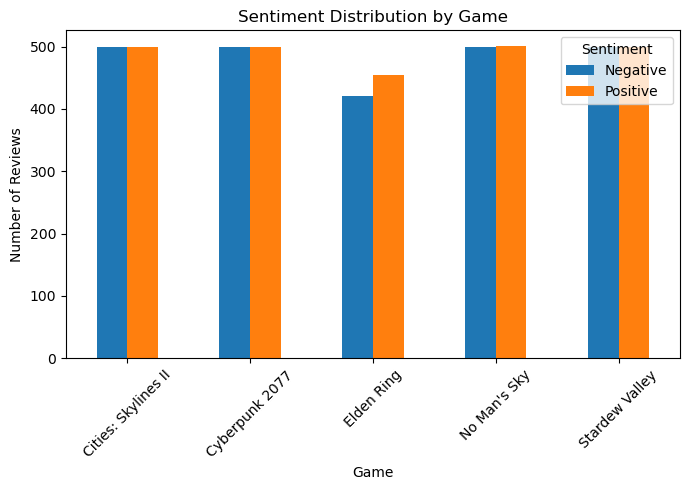

In [262]:
import matplotlib.pyplot as plt

# Plot positive and negative review counts by game
sentiment_counts.plot(kind="bar", figsize=(7, 5))

plt.title("Sentiment Distribution by Game")
plt.xlabel("Game")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

### Analyzing Review Lengths

We calculate the number of words in each review and examine the distribution. This helps us understand how long or short Steam reviews are.

In [72]:
# Calculate the number of words in each review
steam_df["word_count"] = steam_df["clean_review"].str.split().str.len()

# Display summary statistics
print(steam_df["word_count"].describe())

count    4875.000000
mean      112.255179
std       165.502176
min         1.000000
25%        27.000000
50%        54.000000
75%       123.000000
max      1448.000000
Name: word_count, dtype: float64


### Visualizing Review Lengths

We create a histogram to examine the distribution of word counts in Steam reviews. This helps us identify short and long reviews.

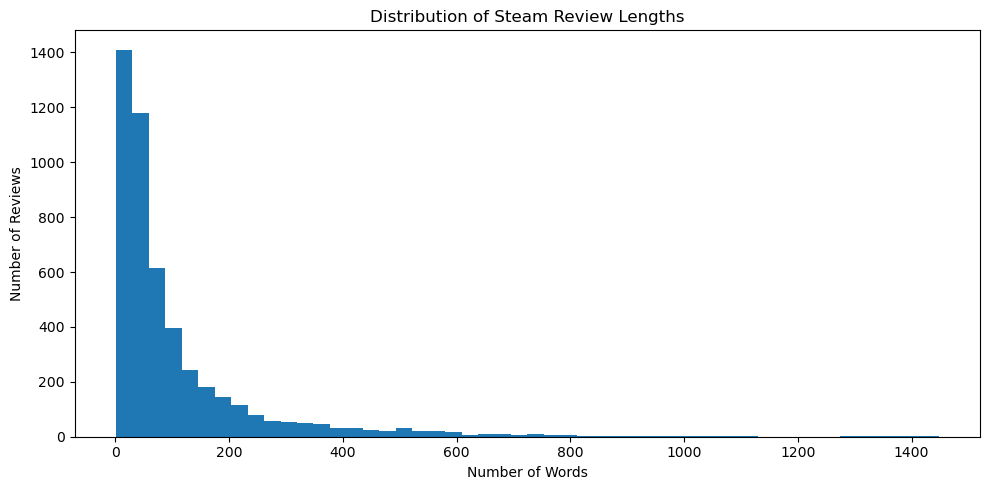

In [74]:
# Plot the distribution of review lengths
plt.figure(figsize=(10, 5))

plt.hist(steam_df["word_count"], bins=50)

plt.title("Distribution of Steam Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

### Examining Short and Long Reviews

We examine the shortest and longest reviews based on word count. This helps us understand the variation in review lengths and identify possible outliers.

In [76]:
# Display the 5 shortest reviews
print("Shortest reviews:")
display(steam_df[["game", "word_count", "review"]].nsmallest(5, "word_count"))

# Display the 5 longest reviews
print("Longest reviews:")
display(steam_df[["game", "word_count", "review"]].nlargest(5, "word_count"))

Shortest reviews:


,game,word_count,review
417,Elden Ring,1,/
730,Elden Ring,1,傻逼宫崎英高找不到自己的妈妈在神秘游戏引擎里做依托稀烂的粪折磨所有想要花费193人民币的抖m
1638,Cyberpunk 2077,1,历经五六年的修复之后还是会出现部分影响游戏体验的BUG，例如部分存档读取期间出现游戏闪退、游...
2266,No Man's Sky,1,玩法多样到即使你就玩其中一个都能玩好久好久，免费更新了怎么怎么久，续作不买我都感觉我对不起她们了
2267,No Man's Sky,1,有耐心慢慢探索星空，是个完美的科幻游戏


Longest reviews:


,game,word_count,review
1538,Cyberpunk 2077,1448,spoilers\nCyberpunk 2077 is one of the only ga...
2791,No Man's Sky,1441,Its too buggy and it really hurts playing it a...
561,Elden Ring,1434,5/10\r\n\r\nElden Ring has mountains of potent...
2519,No Man's Sky,1434,"There was a lot of praise for the game, how it..."
900,Cyberpunk 2077,1411,(Spoiler) Night City is a colossal purgatory f...


### Checking Reviews for Non-English Characters

Although we requested English reviews, some reviews contain Chinese and other non-English characters. We check how many reviews contain non-ASCII characters before deciding how to filter them.

In [78]:
# Find reviews containing non-ASCII characters
non_ascii = steam_df["review"].str.contains(r"[^\x00-\x7F]", regex=True)

# Count reviews containing non-ASCII characters
print("Reviews with non-ASCII characters:", non_ascii.sum())

# Display sample reviews
display(steam_df.loc[non_ascii, ["game", "review"]].head(10))

Reviews with non-ASCII characters: 612


,game,review
2,Elden Ring,Let me start off be saying this game is phenom...
3,Elden Ring,I got Elden Ring as a Christmas present from m...
7,Elden Ring,This is one of those games that will never mak...
9,Elden Ring,Elden Ring was my first souls game. I started ...
10,Elden Ring,Elden Ring feels like a game made with real pa...
12,Elden Ring,"before I played elden ring, I had a small wee ..."
13,Elden Ring,Back in 2011 my friend got me to play Dark Sou...
15,Elden Ring,"First of all, the first gameplay experience is..."
22,Elden Ring,Elden Ring felt like it’s the culmination of a...
28,Elden Ring,[h1] One of the greatest and highest-quality g...


### Checking Reviews with Chinese Characters

Some reviews contain Chinese text even though we requested English reviews. We identify these reviews to better understand the language issues in our dataset.

In [80]:
# Identify reviews containing Chinese characters
chinese_reviews = steam_df["review"].str.contains(r"[\u4e00-\u9fff]", regex=True)

# Count reviews with Chinese characters
print("Reviews containing Chinese characters:", chinese_reviews.sum())

# Display sample reviews
display(steam_df.loc[chinese_reviews, ["game", "review"]].head(10))

Reviews containing Chinese characters: 9


,game,review
209,Elden Ring,**Elden Ring** is easily one of the best actio...
499,Elden Ring,"к сожалению не затянуло, НО Elden Ring и DLC S..."
730,Elden Ring,傻逼宫崎英高找不到自己的妈妈在神秘游戏引擎里做依托稀烂的粪折磨所有想要花费193人民币的抖m
1638,Cyberpunk 2077,历经五六年的修复之后还是会出现部分影响游戏体验的BUG，例如部分存档读取期间出现游戏闪退、游...
2266,No Man's Sky,玩法多样到即使你就玩其中一个都能玩好久好久，免费更新了怎么怎么久，续作不买我都感觉我对不起她们了
2267,No Man's Sky,有耐心慢慢探索星空，是个完美的科幻游戏
3671,Cities: Skylines II,令人失望。最初被经济模拟吸引，期望的是模拟到每个市民怎么生活购物上班最后影响到经济，但很遗憾...
3985,Stardew Valley,Chapter 1: Game Basics & Opening Preparation\n...
4206,Stardew Valley,"[h1] 也许是我人生中玩得最开心的游戏之一。[/h1]\r\n俗语说:""Don't jud..."


### Identifying Mostly Chinese Reviews

We calculate the proportion of Chinese characters in each review. Reviews with more than 30% Chinese characters will be flagged for removal to keep our dataset focused on English text.

In [82]:
# Calculate the proportion of Chinese characters
def chinese_ratio(text):
    chinese = len(re.findall(r"[\u4e00-\u9fff]", text))
    return chinese / len(text) if len(text) > 0 else 0

# Identify mostly Chinese reviews
mostly_chinese = steam_df["review"].apply(chinese_ratio) > 0.30

print("Mostly Chinese reviews:", mostly_chinese.sum())

# Display reviews identified for removal
display(steam_df.loc[mostly_chinese, ["game", "review"]])

Mostly Chinese reviews: 6


,game,review
730,Elden Ring,傻逼宫崎英高找不到自己的妈妈在神秘游戏引擎里做依托稀烂的粪折磨所有想要花费193人民币的抖m
1638,Cyberpunk 2077,历经五六年的修复之后还是会出现部分影响游戏体验的BUG，例如部分存档读取期间出现游戏闪退、游...
2266,No Man's Sky,玩法多样到即使你就玩其中一个都能玩好久好久，免费更新了怎么怎么久，续作不买我都感觉我对不起她们了
2267,No Man's Sky,有耐心慢慢探索星空，是个完美的科幻游戏
3671,Cities: Skylines II,令人失望。最初被经济模拟吸引，期望的是模拟到每个市民怎么生活购物上班最后影响到经济，但很遗憾...
4206,Stardew Valley,"[h1] 也许是我人生中玩得最开心的游戏之一。[/h1]\r\n俗语说:""Don't jud..."


### Removing Mostly Chinese Reviews

We remove the six Chinese reviews to keep the dataset focused on English sentiment analysis.

In [84]:
# Remove the 6 mostly Chinese reviews
steam_df = steam_df.loc[~mostly_chinese].copy()

# Reset row numbers
steam_df = steam_df.reset_index(drop=True)

# Check remaining reviews
print("Total reviews:", len(steam_df))

Total reviews: 4869


### Checking Sentiment Distribution After Cleaning

We check the total number of reviews and the positive and negative sentiment counts after removing mostly Chinese reviews.

In [86]:
# Check total reviews after cleaning
print("Total reviews:", len(steam_df))

# Check positive and negative review counts
print("\nSentiment distribution:")
print(steam_df["voted_up"].value_counts())

Total reviews: 4869

Sentiment distribution:
voted_up
True     2453
False    2416
Name: count, dtype: int64


Our cleaned dataset now contains 4,869 reviews and the sentiment distribution remains well balanced.

### Most Common Words in Steam Reviews

Next, we will identify the most frequently used words in the cleaned reviews. We remove common English stopwords to focus on more meaningful terms.

In [89]:
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Combine and split cleaned reviews into words
words = " ".join(steam_df["clean_review"]).split()

# Remove common stopwords and non-alphabetic words
words = [w for w in words if w.isalpha() and w not in ENGLISH_STOP_WORDS]

# Count the 20 most common words
word_counts = Counter(words)

print("Most common words:")
print(word_counts.most_common(30))

Most common words:
[('game', 8545), ('just', 3195), ('like', 2703), ('really', 1285), ('play', 1276), ('time', 1243), ('good', 1126), ('games', 1075), ('hours', 970), ('new', 907), ('want', 856), ('make', 842), ('story', 839), ('feel', 815), ('feels', 800), ('city', 757), ('world', 755), ('playing', 735), ('love', 710), ('way', 684), ('lot', 671), ('fun', 651), ('played', 633), ('things', 627), ('years', 624), ('great', 610), ('best', 606), ('people', 581), ('better', 570), ('gameplay', 530)]


### Visualizing Most Common Words

We create a bar chart of the 30 most frequently used words in Steam reviews. This helps us identify common topics discussed by players.

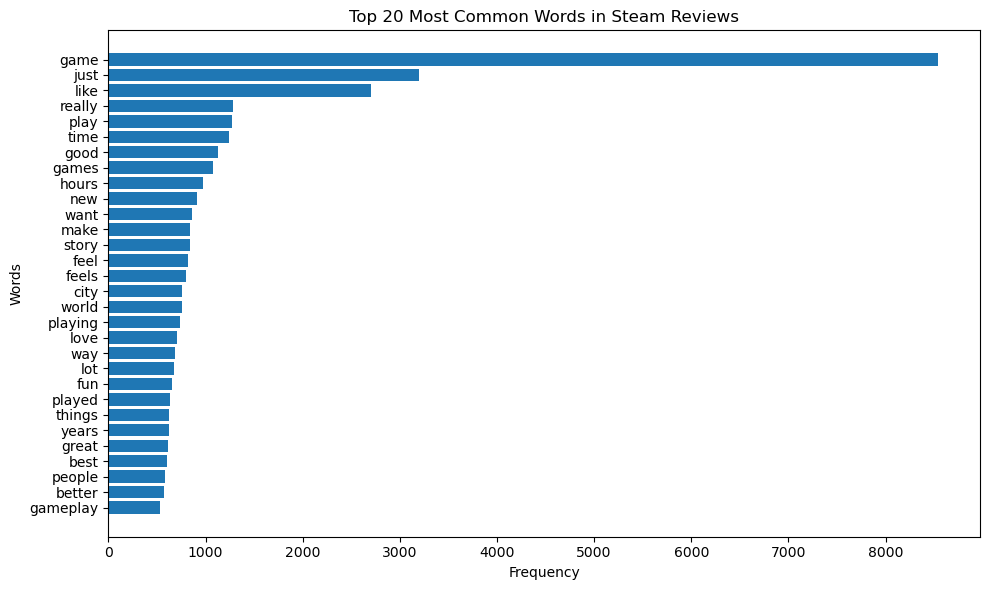

In [91]:
# Get the 20 most common words
top_words = word_counts.most_common(30)

# Separate words and their counts
words, counts = zip(*top_words)

# Create a bar chart
plt.figure(figsize=(10, 6))
plt.barh(words, counts)

plt.title("Top 20 Most Common Words in Steam Reviews")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Comparing Common Words in Positive and Negative Reviews

We examine the 30 most frequent words in positive and negative reviews separately. This helps us understand differences in the language used to express sentiment.

In [93]:
# Separate positive and negative reviews
positive_text = steam_df.loc[steam_df["voted_up"] == True, "clean_review"]
negative_text = steam_df.loc[steam_df["voted_up"] == False, "clean_review"]

# Function to count common words
def common_words(reviews):
    words = " ".join(reviews).split()
    words = [w for w in words if w.isalpha() and w not in ENGLISH_STOP_WORDS]
    return Counter(words).most_common(30)

# Find the top 30 words for each sentiment
positive_words = common_words(positive_text)
negative_words = common_words(negative_text)

print("Top 30 Positive Review Words:")
print(positive_words)

print("\nTop 30 Negative Review Words:")
print(negative_words)

Top 30 Positive Review Words:
[('game', 4137), ('just', 1244), ('like', 1166), ('play', 678), ('good', 658), ('games', 642), ('really', 642), ('time', 604), ('love', 510), ('story', 502), ('best', 491), ('hours', 487), ('city', 486), ('new', 480), ('want', 477), ('world', 448), ('feel', 427), ('great', 404), ('playing', 396), ('played', 391), ('make', 377), ('lot', 364), ('fun', 355), ('feels', 341), ('cyberpunk', 333), ('things', 310), ('way', 303), ('worth', 286), ('years', 286), ('recommend', 285)]

Top 30 Negative Review Words:
[('game', 4408), ('just', 1951), ('like', 1537), ('really', 643), ('time', 639), ('play', 598), ('hours', 483), ('good', 468), ('make', 465), ('feels', 459), ('games', 433), ('new', 427), ('feel', 388), ('way', 381), ('want', 379), ('playing', 339), ('years', 338), ('story', 337), ('things', 317), ('people', 311), ('lot', 307), ('world', 307), ('fun', 296), ('better', 293), ('bad', 274), ('city', 271), ('actually', 266), ('need', 262), ('bugs', 251), ('gamep

### Visualizing Common Words by Sentiment

We create separate bar charts for the 30 most common words in positive and negative reviews. This helps us compare frequently discussed topics between the two sentiment groups.

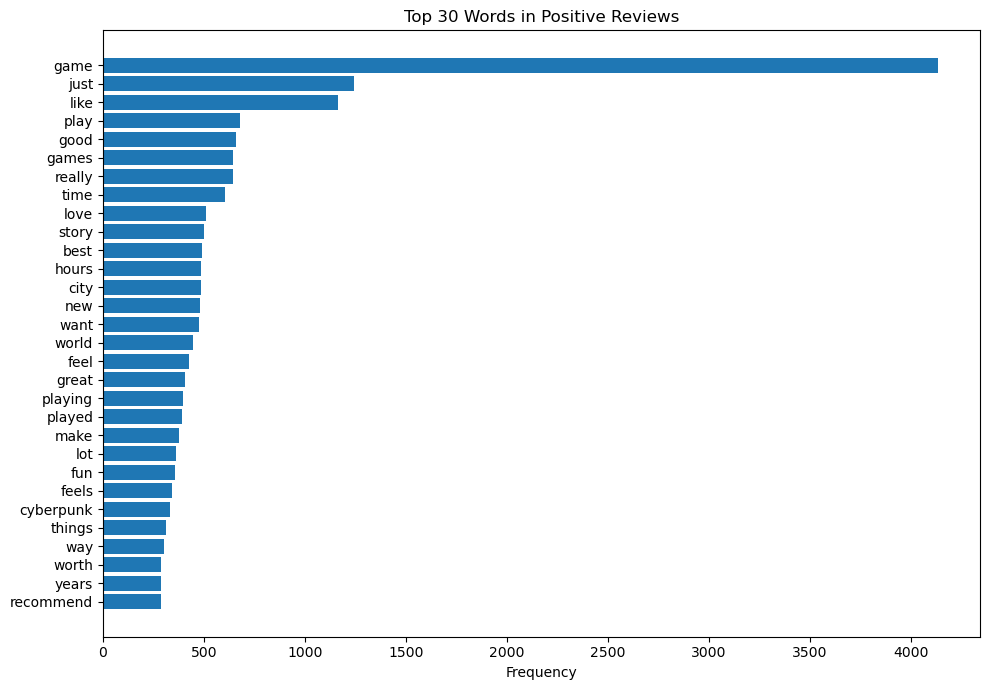

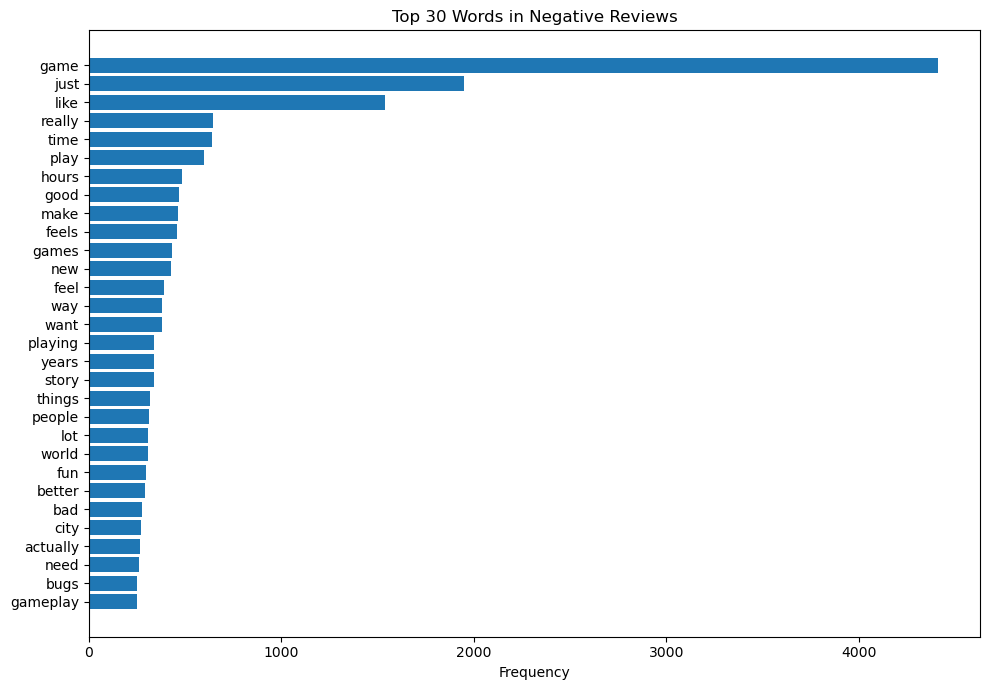

In [95]:
# Create a bar chart for positive reviews
words, counts = zip(*positive_words)

plt.figure(figsize=(10, 7))
plt.barh(words, counts)
plt.title("Top 30 Words in Positive Reviews")
plt.xlabel("Frequency")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Create a bar chart for negative reviews
words, counts = zip(*negative_words)

plt.figure(figsize=(10, 7))
plt.barh(words, counts)
plt.title("Top 30 Words in Negative Reviews")
plt.xlabel("Frequency")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Comparing Review Lengths by Sentiment

We calculate the average number of words in positive and negative reviews to see whether review length differs by sentiment.

In [97]:
# Calculate average word count by sentiment
avg_length = steam_df.groupby("voted_up")["word_count"].mean()

# Display average review lengths
print("Average Review Length:")
print(avg_length.rename(index={True: "Positive", False: "Negative"}).round(2))

Average Review Length:
voted_up
Negative    115.73
Positive    109.10
Name: word_count, dtype: float64


Based on length of reviews; players writing negative reviews tend to provide slightly more detail about their experiences.

### Average Review Length by Sentiment

We compare the average word counts of positive and negative reviews using a bar chart to see whether review length differs by sentiment.

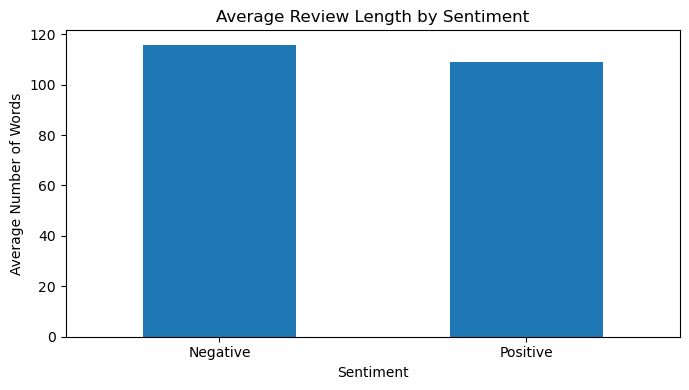

In [250]:
# Calculate average word count by sentiment
avg_length = steam_df.groupby("voted_up")["word_count"].mean()

# Rename sentiment labels
avg_length.index = avg_length.index.map({
    True: "Positive",
    False: "Negative"})

# Plot average review length
plt.figure(figsize=(7, 4))
avg_length.plot(kind="bar")

plt.title("Average Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Number of Words")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Review Length Distribution by Sentiment — Box Plot

A box plot compares the distribution of review lengths for positive and negative reviews. It shows the median, variation, and unusually long reviews (outliers).

<Figure size 800x500 with 0 Axes>

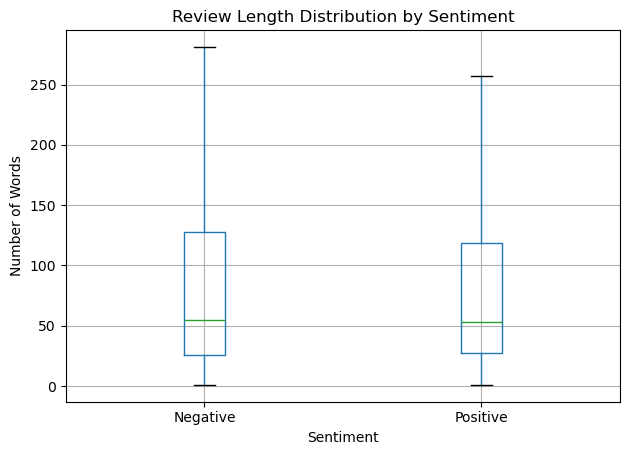

In [287]:
# Box plot of review length by sentiment
plt.figure(figsize=(8, 5))

steam_df.boxplot(column="word_count",by="voted_up",showfliers=False)

plt.title("Review Length Distribution by Sentiment")
plt.suptitle("")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.xticks([1, 2], ["Negative", "Positive"])
plt.tight_layout()
plt.show()

### Saving the Cleaned Steam Reviews Dataset

We save the cleaned dataset containing reviews from all five games. This dataset includes cleaned review text, sentiment labels, and word counts for later modeling.

In [102]:
# Save the cleaned dataset
fp = os.path.join(DATA_DIR, "steam_reviews_cleaned.csv")

steam_df.to_csv(fp, index=False)

# Confirm the saved file
print("Saved:", fp)
print("Total reviews:", len(steam_df))

Saved: data/steam/steam_reviews_cleaned.csv
Total reviews: 4869


## Preparing Data for Sentiment Classification

We split the cleaned Steam reviews into training (70%), validation (15%), and testing (15%) datasets. We use stratified sampling to maintain a similar balance of positive and negative reviews in each dataset.

In [104]:
from sklearn.model_selection import train_test_split

# Select review text and sentiment labels
X = steam_df["clean_review"]
y = steam_df["voted_up"].astype(int)

# Split into 70% training and 30% remaining data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

# Split remaining data equally into validation and testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

# Check dataset sizes
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 3408
Validation: 730
Testing: 731


### Checking Sentiment Balance After Splitting

We check the number of positive and negative reviews in each dataset to confirm that stratified sampling maintained a balanced sentiment distribution.

In [106]:
# Check positive and negative labels in each dataset
print("Training:")
print(y_train.value_counts())

print("\nValidation:")
print(y_val.value_counts())

print("\nTesting:")
print(y_test.value_counts())

Training:
voted_up
1    1717
0    1691
Name: count, dtype: int64

Validation:
voted_up
1    368
0    362
Name: count, dtype: int64

Testing:
voted_up
1    368
0    363
Name: count, dtype: int64


## Sentiment Classification Using TF-IDF and Logistic Regression

We first build a baseline sentiment classification model using TF-IDF to convert review text into numerical features and Logistic Regression to predict positive or negative sentiment.

In [108]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Convert review text into TF-IDF features
tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)

# Train Logistic Regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_tfidf, y_train)

# Predict validation sentiment
y_val_pred = lr_model.predict(X_val_tfidf)

### Evaluating the Logistic Regression Model

We evaluate the baseline model using accuracy, precision, recall, F1-score, and a confusion matrix. These metrics help us understand how well the model classifies positive and negative reviews.

In [110]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate validation accuracy
accuracy = accuracy_score(y_val, y_val_pred)
print("Validation Accuracy:", round(accuracy, 4))

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(y_val, y_val_pred,
                            target_names=["Negative", "Positive"]))

# Display confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

lr_val_acc = accuracy_score(y_val, y_val_pred)
print("Logistic Regression Validation Accuracy:", round(lr_val_acc, 4))

Validation Accuracy: 0.874

Classification Report:
              precision    recall  f1-score   support

    Negative       0.86      0.90      0.88       362
    Positive       0.89      0.85      0.87       368

    accuracy                           0.87       730
   macro avg       0.87      0.87      0.87       730
weighted avg       0.87      0.87      0.87       730

Confusion Matrix:
[[324  38]
 [ 54 314]]
Logistic Regression Validation Accuracy: 0.874


From the confusion matrix:
- 324 negative reviews correctly classified.
- 314 positive reviews correctly classified.
- 38 negative reviews incorrectly classified as positive.
- 54 positive reviews incorrectly classified as negative.
  
The model correctly classified 638 out of 730 reviews.

### Visualizing the Logistic Regression Confusion Matrix

We visualize the confusion matrix to better understand correct and incorrect sentiment predictions made by our baseline model.

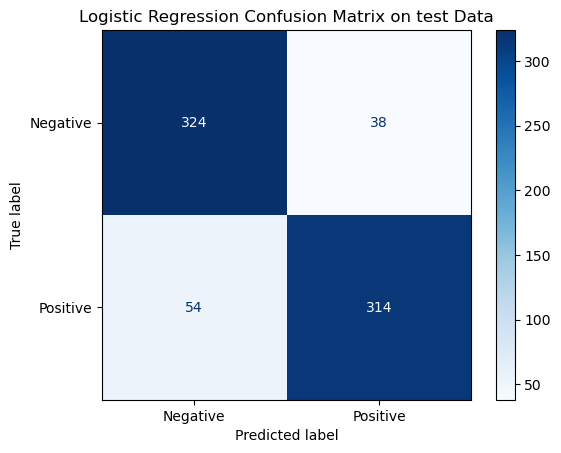

In [264]:
from sklearn.metrics import ConfusionMatrixDisplay

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix on test Data")
plt.show()

### Loading the DistilBERT Tokenizer

We load the pre-trained DistilBERT tokenizer from Hugging Face. The tokenizer converts Steam review text into numerical tokens that the model can process.


In [115]:
#import more libraries
import torch
import transformers
import datasets

from transformers import AutoTokenizer

# Load the pre-trained DistilBERT tokenizer
model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Test the tokenizer with a sample review
sample = "This game is really good!"
tokens = tokenizer(sample)

print(tokenizer.convert_ids_to_tokens(tokens["input_ids"]))

['[CLS]', 'this', 'game', 'is', 'really', 'good', '!', '[SEP]']


### Tokenizing the Steam Reviews

We convert the training and validation reviews into numerical tokens using the DistilBERT tokenizer. We use padding and truncation so the model can process reviews of different lengths.

In [117]:
# Tokenize training reviews
train_tokens = tokenizer(
    X_train.tolist(),
    padding=True,
    truncation=True,
    max_length=256)

# Tokenize validation reviews
val_tokens = tokenizer(
    X_val.tolist(),
    padding=True,
    truncation=True,
    max_length=256)

# Check tokenized dataset sizes
print("Training reviews:", len(train_tokens["input_ids"]))
print("Validation reviews:", len(val_tokens["input_ids"]))
print("Tokens per review:", len(train_tokens["input_ids"][0]))

Training reviews: 3408
Validation reviews: 730
Tokens per review: 256


### Preparing PyTorch Datasets

We convert the tokenized Steam reviews and sentiment labels into PyTorch datasets. These datasets will be used to fine-tune DistilBERT for binary sentiment classification.

In [119]:
from torch.utils.data import TensorDataset

# Convert training tokens and labels into tensors
train_dataset = TensorDataset(
    torch.tensor(train_tokens["input_ids"]),
    torch.tensor(train_tokens["attention_mask"]),
    torch.tensor(y_train.tolist(), dtype=torch.long))

# Convert validation tokens and labels into tensors
val_dataset = TensorDataset(
    torch.tensor(val_tokens["input_ids"]),
    torch.tensor(val_tokens["attention_mask"]),
    torch.tensor(y_val.tolist(), dtype=torch.long))

# Check dataset sizes
print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

Training dataset: 3408
Validation dataset: 730


### Loading the DistilBERT Classification Model

We load the pre-trained DistilBERT model with two output labels: negative (0) and positive (1). The model will be fine-tuned using our Steam reviews dataset.

In [121]:
from transformers import AutoModelForSequenceClassification

# Load DistilBERT with two sentiment labels
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2)

# Use Apple's GPU if available
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model = model.to(device)

print("Model loaded successfully.")
print("Device:", device)

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model loaded successfully.
Device: mps


### Preparing DistilBERT Training Settings

We set the batch size, learning rate, and number of training epochs. We use small batches to manage memory usage on the Mac GPU.

In [123]:
from torch.utils.data import DataLoader
from torch.optim import AdamW

# Create training and validation batches
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8)

# Set optimizer and learning rate
optimizer = AdamW(model.parameters(), lr=2e-5)

# Set number of training epochs
epochs = 2

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Epochs:", epochs)

Training batches: 426
Validation batches: 92
Epochs: 2


### Fine-Tuning DistilBERT

We train DistilBERT for two epochs using our Steam reviews. During training, the model learns to classify reviews as positive or negative. We track training loss and validation accuracy to evaluate its performance.

In [125]:
# Store training results
train_losses = []
val_accuracies = []

for epoch in range(epochs):
    model.train()
    total_loss = 0

    # Train the model
    for input_ids, attention_mask, labels in train_loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels)

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    # Calculate average training loss
    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)

    # Evaluate on validation data
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for input_ids, attention_mask, labels in val_loader:
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask)

            predictions = outputs.logits.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_accuracy = correct / total
    val_accuracies.append(val_accuracy)

    print(f"Epoch {epoch + 1}/{epochs}")
    print(f"Training Loss: {avg_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")

Epoch 1/2
Training Loss: 0.3655
Validation Accuracy: 0.8945
Epoch 2/2
Training Loss: 0.1488
Validation Accuracy: 0.9110


### Evaluating the Fine-Tuned DistilBERT Model

We evaluate DistilBERT using the validation dataset and calculate precision, recall, F1-score, and the confusion matrix. These results will help us compare DistilBERT with our Logistic Regression baseline.

In [127]:
# Collect predictions from the validation dataset
model.eval()
bert_preds = []

with torch.no_grad():
    for input_ids, attention_mask, labels in val_loader:
        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask)

        predictions = outputs.logits.argmax(dim=1)
        bert_preds.extend(predictions.cpu().tolist())

# Display classification metrics
print("DistilBERT Classification Report:")
print(classification_report(
    y_val, bert_preds,
    target_names=["Negative", "Positive"]))

print("Confusion Matrix:")
print(confusion_matrix(y_val, bert_preds))

DistilBERT Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.91      0.91       362
    Positive       0.91      0.91      0.91       368

    accuracy                           0.91       730
   macro avg       0.91      0.91      0.91       730
weighted avg       0.91      0.91      0.91       730

Confusion Matrix:
[[330  32]
 [ 33 335]]


### Saving the Fine-Tuned DistilBERT Model

We save the fine-tuned DistilBERT model and tokenizer for future predictions and model comparison without repeating the training process.

In [129]:
# Save the trained model and tokenizer
save_path = "models/steam_distilbert"

model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

print("DistilBERT model saved:", save_path)

DistilBERT model saved: models/steam_distilbert


### Sentiment Classification Using FLAN-T5 Small

We use the pre-trained FLAN-T5 Small model for sentiment classification. First, we evaluate its zero-shot performance without additional training. This provides another baseline for comparison with Logistic Regression and fine-tuned DistilBERT.

In [131]:
from transformers import AutoModelForSeq2SeqLM

# Load FLAN-T5 Small tokenizer and model
flan_name = "google/flan-t5-small"
flan_tokenizer = AutoTokenizer.from_pretrained(flan_name)
flan_model = AutoModelForSeq2SeqLM.from_pretrained(flan_name)

# Move model to Mac GPU
flan_model = flan_model.to(device)

### Testing FLAN-T5 with Zero-Shot Sentiment Classification

We test FLAN-T5 using a simple prompt to classify a review as positive or negative. Zero-shot classification means the model performs the task without additional training on our Steam reviews.

In [133]:
# Create a sample review and classification prompt
sample_review = "This game is absolutely fun and I really enjoyed playing it."

prompt = f"Classify the sentiment as positive or negative.\nText: {sample_review}\nSentiment:"

# Convert the prompt into tokens
inputs = flan_tokenizer(prompt, return_tensors="pt").to(device)

# Generate sentiment prediction
flan_model.eval()

with torch.no_grad():
    outputs = flan_model.generate(**inputs, max_new_tokens=10)

# Convert prediction into readable text
prediction = flan_tokenizer.decode(outputs[0], skip_special_tokens=True)

print("Review:", sample_review)
print("Predicted Sentiment:", prediction)

Review: This game is absolutely fun and I really enjoyed playing it.
Predicted Sentiment: positive


### Evaluating FLAN-T5 Zero-Shot Sentiment Classification

We use FLAN-T5 to predict sentiment for the validation reviews without fine-tuning. We compare the predictions with the actual sentiment labels to measure model accuracy.

In [135]:
# Store zero-shot predictions
flan_preds = []

flan_model.eval()

with torch.no_grad():
    for review in X_val:
        # Create a sentiment classification prompt
        prompt = f"Classify the sentiment as positive or negative.\nText: {review}\nSentiment:"

        # Tokenize the prompt
        inputs = flan_tokenizer(prompt, return_tensors="pt",
            truncation=True, max_length=256).to(device)

        # Generate prediction
        outputs = flan_model.generate(**inputs, max_new_tokens=10)
        prediction = flan_tokenizer.decode(outputs[0], skip_special_tokens=True)

        # Convert sentiment to numeric labels
        if prediction.strip().lower() == "positive":
            flan_preds.append(1)
        elif prediction.strip().lower() == "negative":
            flan_preds.append(0)
        else:
            flan_preds.append(-1)

# Check predictions
print("Total predictions:", len(flan_preds))
print("Unrecognized predictions:", flan_preds.count(-1))

Total predictions: 730
Unrecognized predictions: 9


### Evaluating FLAN-T5 Zero-Shot Performance

We calculate accuracy, precision, recall, and F1-score for FLAN-T5. Unrecognized predictions are counted as incorrect rather than manually corrected.

In [137]:
# Calculate accuracy, including unrecognized predictions as incorrect
flan_accuracy = accuracy_score(y_val, flan_preds)

print("FLAN-T5 Validation Accuracy:", round(flan_accuracy, 4))

# Calculate classification metrics
print("\nClassification Report:")
print(classification_report(
    y_val, flan_preds,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

# Display confusion matrix, including unrecognized predictions
print("Confusion Matrix:")
print(confusion_matrix(y_val, flan_preds, labels=[0, 1, -1]))

FLAN-T5 Validation Accuracy: 0.8603

Classification Report:
              precision    recall  f1-score   support

    Negative       0.83      0.92      0.87       362
    Positive       0.92      0.80      0.86       368

   micro avg       0.87      0.86      0.87       730
   macro avg       0.88      0.86      0.87       730
weighted avg       0.88      0.86      0.87       730

Confusion Matrix:
[[334  24   4]
 [ 69 294   5]
 [  0   0   0]]


### Comparing Validation Accuracy Across Models

We compare the validation accuracy of Logistic Regression, fine-tuned DistilBERT, and zero-shot FLAN-T5 to identify the best-performing approach.

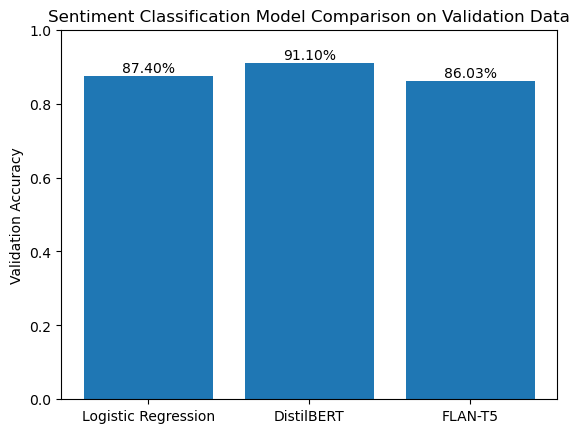

In [291]:
# Store model names and validation accuracy
model_names = ["Logistic Regression", "DistilBERT", "FLAN-T5"]
accuracies  = [lr_val_acc, val_accuracies[-1], flan_accuracy]

# Compare model performance
plt.bar(model_names, accuracies)

plt.ylabel("Validation Accuracy")
plt.title("Sentiment Classification Model Comparison on Validation Data")
plt.ylim(0, 1)

# Display accuracy above each bar
for i, accuracy in enumerate(accuracies):
    plt.text(i, accuracy + 0.01, f"{accuracy:.2%}", ha="center")

plt.show()

### Final Test Evaluation -- Logistic Regression

We evaluate the trained TF-IDF Logistic Regression model on the held-out test dataset using accuracy, precision, recall, F1-score, and a confusion matrix.

Logistic Regression Test Accuracy: 0.8796

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.88      0.88       363
           1       0.88      0.88      0.88       368

    accuracy                           0.88       731
   macro avg       0.88      0.88      0.88       731
weighted avg       0.88      0.88      0.88       731



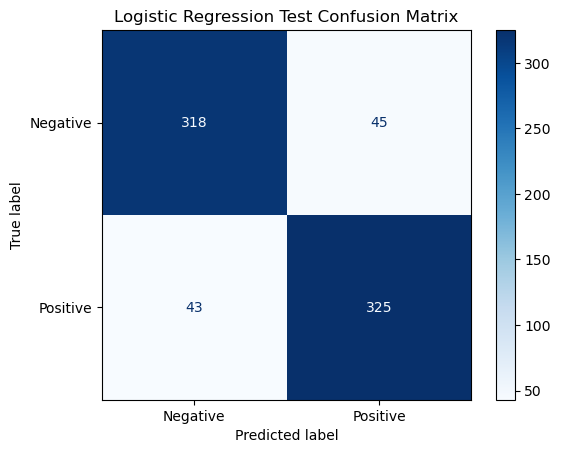

In [276]:
# Transform test reviews using the existing TF-IDF vectorizer
X_test_tfidf = tfidf.transform(X_test)

# Predict sentiment on the test dataset
lr_test_pred = lr_model.predict(X_test_tfidf)

# Evaluate model performance
lr_test_acc = accuracy_score(y_test, lr_test_pred)

print("Logistic Regression Test Accuracy:", round(lr_test_acc, 4))
print("\nClassification Report:")
print(classification_report(y_test, lr_test_pred))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, lr_test_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues")
plt.title("Logistic Regression Test Confusion Matrix")
plt.show()

### Final Test Evaluation --> DistilBERT

We evaluate the fine-tuned DistilBERT model on the held-out test dataset using accuracy, precision, recall, F1-score, and a confusion matrix.

DistilBERT Test Accuracy: 0.9261
              precision    recall  f1-score   support

           0       0.92      0.93      0.93       363
           1       0.93      0.92      0.93       368

    accuracy                           0.93       731
   macro avg       0.93      0.93      0.93       731
weighted avg       0.93      0.93      0.93       731



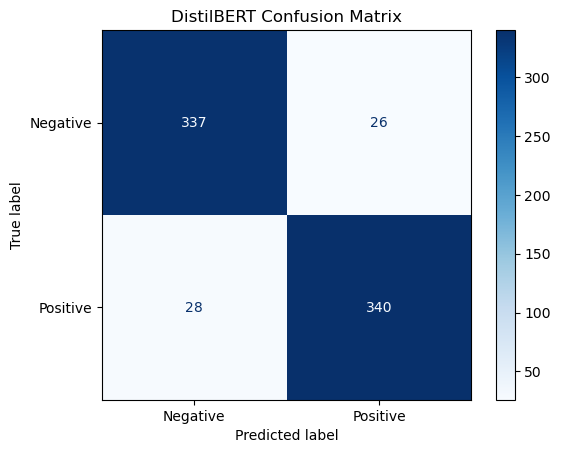

In [278]:
# Load the saved fine-tuned DistilBERT model on CPU
model = AutoModelForSequenceClassification.from_pretrained(
    "models/steam_distilbert").to("cpu")

model.eval()

# Tokenize test reviews
test_tokens = tokenizer(X_test.tolist(),padding=True,truncation=True,max_length=256, return_tensors="pt")

# Create test DataLoader
test_dataset = TensorDataset(
    test_tokens["input_ids"], test_tokens["attention_mask"])

test_loader = DataLoader(test_dataset, batch_size=8)

# Predict sentiment using CPU
bert_test_pred = []

model.eval()

with torch.no_grad():
    for input_ids, attention_mask in test_loader:
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask)
        bert_test_pred.extend(
            outputs.logits.argmax(dim=1).tolist())

# Evaluate predictions
bert_test_acc = accuracy_score(y_test, bert_test_pred)

print("DistilBERT Test Accuracy:", round(bert_test_acc, 4))
print(classification_report(y_test, bert_test_pred))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, bert_test_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues")

plt.title("DistilBERT Confusion Matrix")
plt.show()

### Final Test Evaluation --> FLAN-T5 Zero-Shot

We evaluate the pretrained FLAN-T5 Small model on the held-out test dataset without additional fine-tuning. This allows us to compare a generative zero-shot approach with Logistic Regression and fine-tuned DistilBERT.

In [145]:
# Load the original pretrained FLAN-T5 model on CPU-- I need to do this to make sure I run the model on CPU memory
flan_model = AutoModelForSeq2SeqLM.from_pretrained(
    "google/flan-t5-small").to("cpu")
flan_model.eval()
print("FLAN-T5 load on CPU.")

FLAN-T5 load on CPU.


In [270]:
# Generate zero-shot predictions on the test dataset
flan_test_pred = []

for review in X_test:
    prompt  = f"Classify the sentiment as positive or negative.\nText: {review}\nSentiment:"

    inputs = flan_tokenizer(prompt,return_tensors="pt",truncation=True, max_length=256 )

    with torch.no_grad():
        outputs = flan_model.generate(
            **inputs,
            max_new_tokens=10)

    prediction = flan_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True).strip().lower()

    if prediction == "positive":
        flan_test_pred.append(1)
    elif prediction == "negative":
        flan_test_pred.append(0)
    else:
        flan_test_pred.append(-1)

print("Total predictions:", len(flan_test_pred))
print("Unrecognized predictions:", flan_test_pred.count(-1))# -1 = Unrecognized prediction based on our earlier assesment above

Total predictions: 731
Unrecognized predictions: 0


### Final Test Evaluation — FLAN-T5 Zero-Shot

We evaluate FLAN-T5 using accuracy, precision, recall, F1-score, and a confusion matrix on the same 731 test reviews used for the other models.

FLAN-T5 Test Accuracy: 0.8796
              precision    recall  f1-score   support

           0       0.84      0.94      0.89       363
           1       0.93      0.82      0.87       368

    accuracy                           0.88       731
   macro avg       0.88      0.88      0.88       731
weighted avg       0.89      0.88      0.88       731



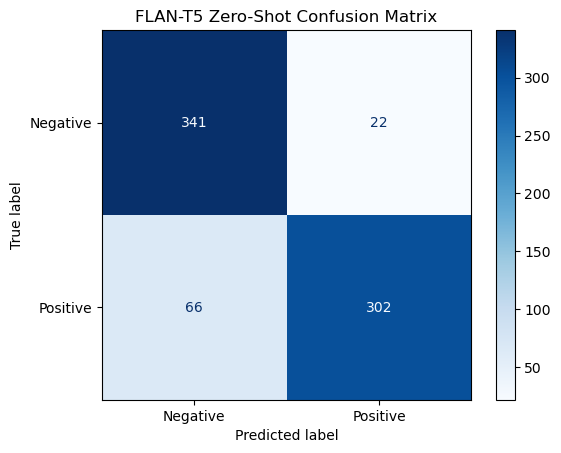

In [279]:
# Calculate test accuracy
flan_test_acc = accuracy_score(y_test, flan_test_pred)

print("FLAN-T5 Test Accuracy:", round(flan_test_acc, 4))
print(classification_report(y_test, flan_test_pred))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, flan_test_pred,
    display_labels=["Negative", "Positive"],cmap="Blues")

plt.title("FLAN-T5 Zero-Shot Confusion Matrix")
plt.show()

### Final Model Performance Comparison

Three sentiment classification approaches were evaluated on the same held-out test dataset of 731 Steam reviews.

Fine-tuned DistilBERT achieved the highest accuracy (92.61%), followed by zero-shot FLAN-T5 (87.96%) and TF-IDF with Logistic Regression (87.96%).

Fine-tuned DistilBERT outperformed the traditional Logistic Regression baseline, while zero-shot FLAN-T5 achieved the same accuracy as Logistic Regression without task-specific training.

In [150]:
# Compare final test accuracy across models
results = pd.DataFrame({
    "Model": ["Logistic Regression", "DistilBERT", "FLAN-T5 Zero-Shot"],
    "Test Accuracy": [lr_test_acc, bert_test_acc, flan_test_acc]})

print(results.round(4))

                 Model  Test Accuracy
0  Logistic Regression         0.8796
1           DistilBERT         0.9261
2    FLAN-T5 Zero-Shot         0.8796


## Conclusion and Limitations

### Conclusion
This project compared three sentiment analysis approaches using Steam user reviews.

- **DistilBERT** achieved the highest test accuracy of  92.61%.
- **FLAN-T5 Zero-Shot** achieved 87.96% accuracy without fine-tuning.
- **Logistic Regression** achieved 87.96% , providing a strong baseline.

The results suggest that transformer-based models can improve sentiment classification compared with traditional machine learning methods. FLAN-T5 also demonstrated that prompt-based classification can perform well without task-specific training.

### Limitations
- The dataset contains 4,869 English-language reviews from only five Steam games.
- Sarcasm, mixed opinions, and gaming-specific expressions may affect prediction accuracy.
- FLAN-T5 was evaluated using zero-shot prompting rather than fine-tuning.
- Fine-tuning generative models was limited by memory and training stability issues.
- Results may not generalize to reviews from other games or platforms.

### Future Improvements
Future work could include collecting more reviews, testing additional transformer models and investigating incorrect predictions.

### References:

OpenAI. (2026). ChatGPT [Large language model]. https://chatgpt.com/
